# PDF parsing with PyMuPDF and OCR

This notebook explores what a PDF actually gives to a parser, and what must be recovered with OCR when it gives almost nothing.

A PDF page is a list of drawing instructions: place this glyph at these coordinates, stroke this path, paint this image. Words, paragraphs, equations, and tables are what a reader perceives, but they are not necessarily stored as such. Each experiment below looks at one gap between what a page shows and what the file encodes.

Two documents are used:

- `ch2.pdf` is a 68-page slide deck made with LaTeX Beamer. It is born-digital, with native text, mathematical notation, vector plots, an embedded raster figure, and a table.
- `scanned.pdf` is a three-page scanned letter. It looks like a text document, but its content is an image of paper.

The experiments move from document-level inspection, to the text geometry and structure of a single slide, to non-text content, and finally to OCR on the scan.

## Setup

Input paths are resolved from the repository root, so the notebook works whether Jupyter starts at the root or inside `notebooks/experiments/`. PyMuPDF handles parsing, rendering, and OCR; NumPy and Matplotlib are only used to display rendered pages (`pip install pymupdf numpy matplotlib`). PyMuPDF calls the Tesseract engine built into MuPDF, so no separate Tesseract program is needed, but the English model `eng.traineddata` must be present in `resources/tessdata/`.

`pixmap_to_array` converts a rendered page (a PyMuPDF `Pixmap`) into a `(height, width, channels)` array for `imshow`. It trims any padding at the end of each pixel row (`stride`) before reshaping.

In [40]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pymupdf
from matplotlib.patches import Rectangle

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
SLIDES_PDF = PROJECT_ROOT / "data" / "documents" / "ch2.pdf"
SCANNED_PDF = PROJECT_ROOT / "data" / "documents" / "scanned.pdf"
TESSDATA_DIR = PROJECT_ROOT / "resources" / "tessdata"

required_files = [
    SLIDES_PDF,
    SCANNED_PDF,
    TESSDATA_DIR / "eng.traineddata",
]
for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Required input not found: {path.resolve()}")


def pixmap_to_array(pixmap):
    """Return a PyMuPDF Pixmap as a (height, width, channels) uint8 array."""
    rows = np.frombuffer(pixmap.samples, dtype=np.uint8)
    rows = rows.reshape(pixmap.height, pixmap.stride)[:, : pixmap.width * pixmap.n]
    return rows.reshape(pixmap.height, pixmap.width, pixmap.n)


print("PyMuPDF version:", pymupdf.__version__)
print("Inputs:", ", ".join(str(path) for path in required_files))

PyMuPDF version: 2.1
Inputs: ch2.pdf, scanned.pdf, tessdata/eng.traineddata


## 1. Document-level inspection

Before extracting content, it helps to know what kind of file we have. Metadata records the software that made it, and the page rectangle defines the coordinate system used by every later bounding box. PyMuPDF measures in PDF points (1 pt = 1/72 inch), with the origin at the top-left corner and *y* increasing downwards.

In [41]:
for pdf_path in [SLIDES_PDF, SCANNED_PDF]:
    with pymupdf.open(pdf_path) as document:
        metadata = document.metadata
        first_page = document[0]

        print(f"\n{pdf_path.name}")
        print("  Pages:", document.page_count)
        print("  Format:", metadata.get("format"))
        print("  Title:", repr(metadata.get("title")))
        print("  Creator:", repr(metadata.get("creator")))
        print("  Producer:", repr(metadata.get("producer")))
        print("  Encrypted:", document.is_encrypted)
        print("  Table-of-contents entries:", len(document.get_toc()))
        print("  First-page dimensions:", first_page.rect)
        print("  First-page rotation:", first_page.rotation)


ch2.pdf
  Pages: 68
  Format: PDF 1.5
  Title: 'The prior distribution'
  Creator: 'LaTeX with Beamer class'
  Producer: 'MiKTeX pdfTeX-1.40.24'
  Encrypted: False
  Table-of-contents entries: 5
  First-page dimensions: Rect(0.0, 0.0, 362.8349914550781, 272.1260070800781)
  First-page rotation: 0

scanned.pdf
  Pages: 3
  Format: PDF 1.5
  Title: 'Scanned Document'
  Creator: 'HardCopy'
  Producer: 'Lexmark X792'
  Encrypted: False
  Table-of-contents entries: 0
  First-page dimensions: Rect(0.0, 0.0, 612.0, 792.0)
  First-page rotation: 0


The two files differ at every level. `ch2.pdf` was created by LaTeX with the Beamer class. Its 362.83 × 272.13 pt pages are Beamer's 4:3 format (12.8 × 9.6 cm), and it has five table-of-contents (bookmark) entries. `scanned.pdf` has US Letter pages (612 × 792 pt = 8.5 × 11 in) and no table of contents. Its creator and producer fields, `HardCopy` and `Lexmark X792`, point to a scanner. Neither file is encrypted, and neither first page is rotated, so page coordinates can be used as they are.

Metadata only says how a file was produced. It does not say whether a given page stores its content as text, vector paths, or pixels, and a scanner-made PDF can still contain text objects, as section 6 shows. That has to be checked page by page.

## 2. Native text extraction and reading order

On a born-digital page the characters are already in the file, so the main question is the order in which they come out. By default, `get_text("text")` returns text in the order it was written in the page's content stream. With `sort=True`, PyMuPDF reorders the text by position, from top-left to bottom-right, to approximate reading order. Page 9 is a good test because it mixes ordinary prose with an inline fraction and integrals.

In [42]:
with pymupdf.open(SLIDES_PDF) as document:
    math_page = document[8]
    default_text = math_page.get_text("text")
    sorted_text = math_page.get_text("text", sort=True)

print("DEFAULT EXTRACTION:\n")
print(default_text)
print("SORTED EXTRACTION:\n")
print(sorted_text)

DEFAULT EXTRACTION:

Why the support of the prior matters. II
• In the dominated case this is Bayes’ rule: π(A|x) =
1
m(x)
R
A f(x|θ)π(θ) dθ = 0
as soon as π(A) =
R
A π(θ) dθ = 0.
• Cromwell’s rule (Lindley 1985): never give prior probability 0 to a possibility
that is not logically impossible. Example: truncating a prior to θ ∈[0, 10] for
convenience excludes θ > 10 forever, however strongly the data point there.
• Quantitative version (same computation): π(A|x) ≤π(A) supθ∈A f(x|θ)/m(x).
A region of small prior mass can be recovered only by a large likelihood ratio.
• Chapter 8 (asymptotic properties): a sufficient condition for posterior
consistency at θ0 is that π gives positive mass to the Kullback-Leibler
neighbourhoods of Pθ0 (Schwartz 1965). This slide shows why positive prior
mass around θ0 is in any case necessary.
The prior distribution
9 / 68

SORTED EXTRACTION:

          Why the support of the prior matters. II



• In the dominated case this is Bayes’ rule: π(A|x) = m(x)1

Both versions recover the title, the four bullet points, and the footer, and they agree on the ordinary prose. They differ on the first formula, $\pi(A \mid x) = \frac{1}{m(x)} \int_A f(x \mid \theta)\,\pi(\theta)\,d\theta$. The default extraction puts the numerator `1`, the denominator `m(x)`, the integral sign, and its subscript `A` on separate lines, because they were written as separate, vertically offset pieces. Sorting puts them back on one line but produces `m(x)1`, with the denominator before the numerator. Section 4 shows why: `m` starts slightly to the left of `1`.

Two other problems appear in both outputs. First, the integral sign comes out as the letter `R`. It is drawn with the TeX font CMEX9, where the large integral sits at character code 0x52, the ASCII code of `R`. Since the extracted text shows no Unicode mapping for it, the raw code is returned instead. Second, some spaces are missing, as in `θ ∈[0, 10]` and `≤π(A)`. TeX positions math symbols with horizontal shifts rather than space characters, so PyMuPDF has to infer spaces from gaps between glyphs, and some of these gaps are too small.

Geometric sorting improves reading order, but no ordering can rebuild an equation. The PDF stores glyph positions, not a fraction or the limits of an integral, so recovering LaTeX or MathML from this page would need a separate math-recognition step.

## 3. Words and their bounding boxes

Plain text discards position. `get_text("words")` keeps it: each word comes with its bounding box `(x0, y0, x1, y1)` in page coordinates and three indices `(block, line, word)` that place it in PyMuPDF's layout hierarchy. To check the coordinates, the page is rendered at 144 dpi and the first 25 boxes are drawn on it. Points are defined as 1/72 inch, so converting points to pixels at 144 dpi means multiplying by 144 / 72 = 2. The code computes this factor from the pixmap and page sizes.

Total words: 148
Tuple fields: (x0, y0, x1, y1, text, block, line, word)
(127.23300170898438, 9.100998878479004, 155.05027770996094, 23.44719886779785, 'Why', 0, 0, 0)
(158.63682556152344, 9.100998878479004, 176.1678924560547, 23.44719886779785, 'the', 0, 0, 1)
(179.7544403076172, 9.100998878479004, 222.79302978515625, 23.44719886779785, 'support', 0, 0, 2)
(226.37957763671875, 9.100998878479004, 238.3299560546875, 23.44719886779785, 'of', 0, 0, 3)
(241.91650390625, 9.100998878479004, 259.44757080078125, 23.44719886779785, 'the', 0, 0, 4)
(263.03411865234375, 9.100998878479004, 290.9231262207031, 23.44719886779785, 'prior', 0, 0, 5)
(294.5096740722656, 9.100998878479004, 340.3314514160156, 23.44719886779785, 'matters.', 0, 0, 6)
(344.7787780761719, 9.100998878479004, 354.3333435058594, 23.44719886779785, 'II', 0, 0, 7)
(38.68299865722656, 65.0522689819336, 43.29172897338867, 74.01866912841797, '•', 1, 0, 0)
(48.27199935913086, 66.6209716796875, 55.74101257324219, 75.58737182617188, 'In

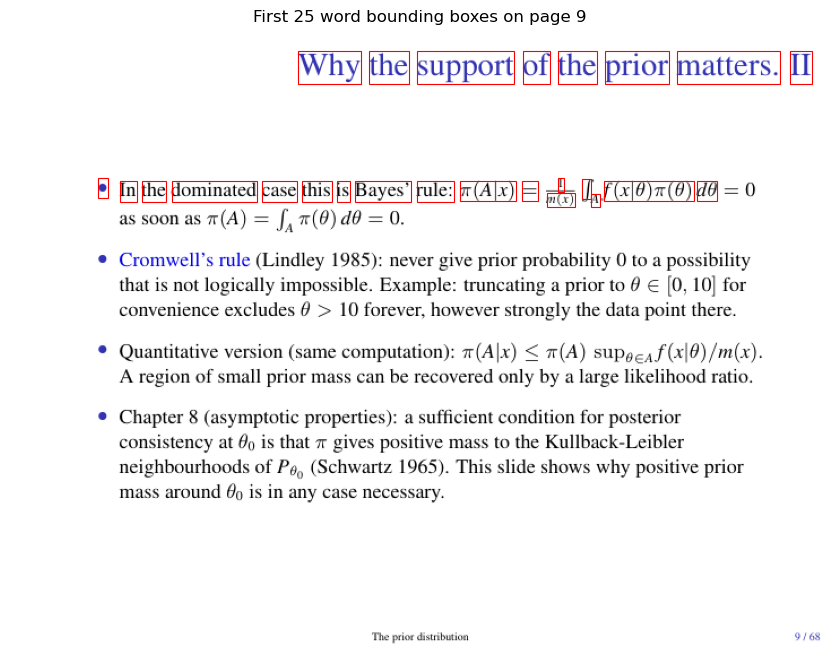

In [43]:
with pymupdf.open(SLIDES_PDF) as document:
    page = document[8]
    words = page.get_text("words")
    pixmap = page.get_pixmap(dpi=144, alpha=False)
    page_rect = page.rect

print("Total words:", len(words))
print("Tuple fields: (x0, y0, x1, y1, text, block, line, word)")
for word in words[:10]:
    print(word)

image = pixmap_to_array(pixmap)
scale_x = pixmap.width / page_rect.width
scale_y = pixmap.height / page_rect.height

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

for x0, y0, x1, y1, *_ in words[:25]:
    ax.add_patch(
        Rectangle(
            (x0 * scale_x, y0 * scale_y),
            (x1 - x0) * scale_x,
            (y1 - y0) * scale_y,
            fill=False,
            edgecolor="red",
            linewidth=0.8,
        )
    )

ax.set_title("First 25 word bounding boxes on page 9")
ax.axis("off")
plt.show()

The page has 148 words. The title words all share `y0 ≈ 9.10` and `y1 ≈ 23.45`, a small *y* that places them at the top of the page, and they have the indices block 0, line 0. The first bullet starts block 1.

In the figure, the 25 boxes fit the title and the first line of the first bullet tightly, which confirms both the coordinates and the scaling. The boxes also show what PyMuPDF counts as a word: a run of characters between spaces. So `π(A|x)` is a single box, while the fraction becomes two tiny boxes, one above the other, and the integral sign and its subscript `A` become two more. A bounding box says where an item is, not what role it plays. Nothing in these tuples says that the small `1` is the numerator of `m(x)`.

## 4. Blocks, lines, spans, and fonts

`get_text("dict")` exposes the hierarchy behind the word list. A page contains blocks (roughly paragraphs, or images), blocks contain lines, and lines contain spans. A span is a run of characters with the same font, size, and color, so a new span starts whenever the formatting changes. This makes the internal structure of the equation, or rather its lack of structure, visible.

In [44]:
with pymupdf.open(SLIDES_PDF) as document:
    page_dict = document[8].get_text("dict")

text_blocks = [block for block in page_dict["blocks"] if block["type"] == 0]
lines = [line for block in text_blocks for line in block["lines"]]
spans = [span for line in lines for span in line["spans"]]

print("Text blocks:", len(text_blocks))
print("Lines:", len(lines))
print("Spans:", len(spans))
print("\nFirst 20 spans:")

for span in spans[:20]:
    print(
        {
            "text": span["text"],
            "font": span["font"],
            "size": round(span["size"], 2),
            "bbox": tuple(round(value, 2) for value in span["bbox"]),
        }
    )

Text blocks: 10
Lines: 20
Spans: 138

First 20 spans:
{'text': 'Why the support of the prior matters.', 'font': 'NimbusRomNo9L-Regu', 'size': 14.35, 'bbox': (127.23, 9.1, 340.33, 23.45)}
{'text': ' ', 'font': 'NimbusRomNo9L-Regu', 'size': 14.35, 'bbox': (340.33, 9.1, 344.78, 23.45)}
{'text': 'II', 'font': 'NimbusRomNo9L-Regu', 'size': 14.35, 'bbox': (344.78, 9.1, 354.33, 23.45)}
{'text': '•', 'font': 'CMSY9', 'size': 8.97, 'bbox': (38.68, 65.05, 43.29, 74.02)}
{'text': ' ', 'font': 'NimbusRomNo9L-Regu', 'size': 8.97, 'bbox': (43.29, 65.38, 48.27, 74.34)}
{'text': 'In the dominated case this is Bayes’ rule:', 'font': 'NimbusRomNo9L-Regu', 'size': 8.97, 'bbox': (48.27, 66.62, 195.95, 75.59)}
{'text': ' ', 'font': 'CMMI9', 'size': 8.97, 'bbox': (195.95, 66.41, 198.73, 75.38)}
{'text': 'π', 'font': 'CMMI9', 'size': 8.97, 'bbox': (198.73, 66.41, 204.0, 75.38)}
{'text': '(', 'font': 'CMR9', 'size': 8.97, 'bbox': (204.32, 66.41, 207.91, 75.38)}
{'text': 'A', 'font': 'NimbusRomNo9L-ReguItal', 

Page 9 has 10 text blocks, 20 lines, and 138 spans. The title is essentially one 14.35 pt span, followed by a space and `II`. The first equation is split into many short spans because each kind of symbol uses a different font: CMMI9 (math italic) for `π`, CMR9 for parentheses and `=`, CMSY9 for `|` and the bullet, CMEX9 for the integral, and the Times-like NimbusRomNo9L for the letters `A` and `x`.

The fraction is the clearest case. Its numerator `1` and denominator `m(x)` are 5.98 pt spans, smaller than the 8.97 pt surrounding text, and they sit at different heights: `1` has `y0 = 65.21`, while `m` has `y0 = 71.83`. Horizontally, `m` starts at `x0 = 237.02`, left of the `1` at `x0 = 241.89`. This explains both outputs from section 2. In stream order the two parts are separate lines, and once sorting merges them into one line, `m(x)` comes first.

The span level keeps much more than plain text, including fonts, sizes, and exact positions. A math-aware tool could use font names and vertical offsets as clues, but the fraction itself is not stored anywhere and would have to be inferred from the geometry.

## 5. Raster images, vector drawings, and tables

Not all page content is text. A figure can be stored in two very different ways: as a raster image (a grid of pixels) or as vector drawings (paths made of lines, curves, and filled shapes). Tables are a third case. In a PDF they are usually just positioned text plus a few lines, and their row and column structure has to be reconstructed.

Three slides are compared: page 17 (two contour plots), page 49 (a table of conjugate priors), and page 65 (a figure taken from a paper). For each page, `get_images(full=True)` lists the embedded raster images (`get_image_info()` adds their pixel size and position), `get_drawings()` lists the vector paths, and `find_tables()` looks for tables using ruling lines and text alignment. The pages are then rendered, with the detected table outlined in red and the images in blue.

Page 17
  Words: 167
  Raster images: 0
  Vector drawings: 67
  Detected tables: 0
Page 49
  Words: 216
  Raster images: 0
  Vector drawings: 10
  Detected tables: 1
    16 rows x 1 column(s), bbox (28.35, 48.19, 334.49, 241.27)
    First two rows: [['Usual conjugate pairs. n i .i .d . observations . Notation: s := P i xi,'], ['Q := P i(xi −µ)2 , x(n) := maxi xi, (s1, . . . , sk) the category counts . Ga(a, b): shape']]
Page 65
  Words: 39
  Raster images: 2
    1 x 1 px
    4346 x 2536 px
  Vector drawings: 2
  Detected tables: 0


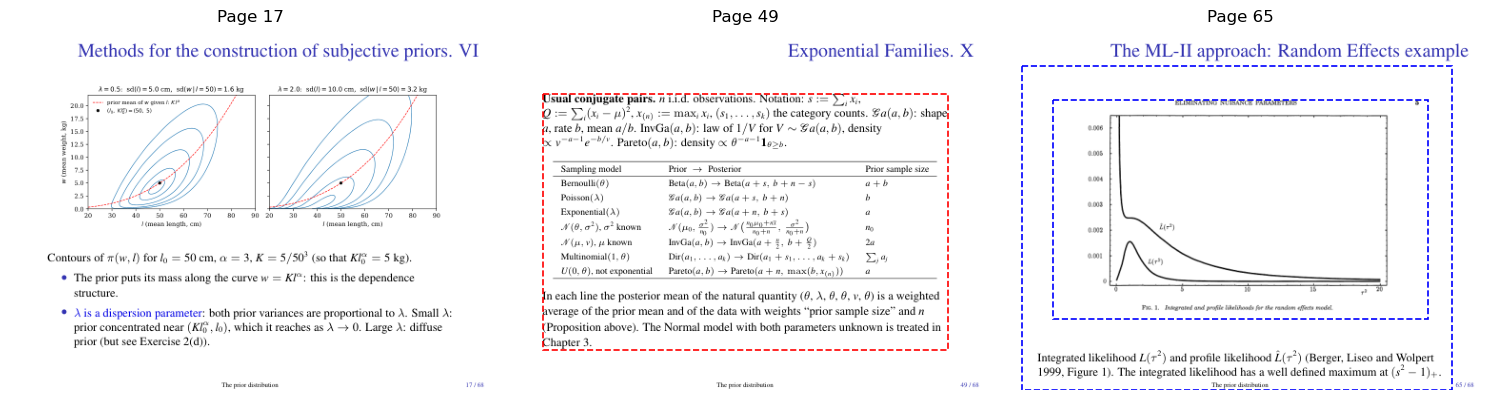

In [45]:
page_numbers = [17, 49, 65]
fig, axes = plt.subplots(1, len(page_numbers), figsize=(15, 4))

with pymupdf.open(SLIDES_PDF) as document:
    for ax, page_number in zip(axes, page_numbers):
        page = document[page_number - 1]
        image_info = page.get_image_info()
        detected_tables = page.find_tables().tables

        print(f"Page {page_number}")
        print("  Words:", len(page.get_text("words")))
        print("  Raster images:", len(page.get_images(full=True)))
        for info in image_info:
            print(f"    {info['width']} x {info['height']} px")
        print("  Vector drawings:", len(page.get_drawings()))
        print("  Detected tables:", len(detected_tables))
        for table in detected_tables:
            print(f"    {table.row_count} rows x {table.col_count} column(s),",
                  "bbox", tuple(round(value, 2) for value in table.bbox))
            print("    First two rows:", table.extract()[:2])

        # Render the page and outline tables (red) and images (blue),
        # clipped to the visible page area.
        pixmap = page.get_pixmap(dpi=100, alpha=False)
        scale = pixmap.width / page.rect.width
        ax.imshow(pixmap_to_array(pixmap))
        outlines = [(table.bbox, "red") for table in detected_tables]
        outlines += [(info["bbox"], "blue") for info in image_info]
        for bbox, color in outlines:
            rect = pymupdf.Rect(bbox) & page.rect
            ax.add_patch(
                Rectangle(
                    (rect.x0 * scale, rect.y0 * scale),
                    rect.width * scale,
                    rect.height * scale,
                    fill=False,
                    edgecolor=color,
                    linewidth=1.2,
                    linestyle="--",
                )
            )
        ax.set_title(f"Page {page_number}")
        ax.axis("off")

plt.tight_layout()
plt.show()

**Vector versus raster.** Page 17 has no raster image but 67 vector drawings: its two contour plots are made of paths, so their curves are stored as geometry, and they stay sharp at any zoom. Page 65 is the opposite. One of its two images is only 1 × 1 px, so it carries no visible content, even though its placement rectangle covers most of the slide. The other, 4346 × 2536 px, is the whole figure, including its axes, curves, labels, and printed caption. All of that is pixels, which is why the page yields only 39 words, enough for the slide title, the two-line caption below the figure, and the footer. A plot that looks the same on screen can therefore be fully inspectable (vector) or opaque without OCR (raster).

**Table detection.** `find_tables()` reports one table on page 49, but the result is wrong. It has 16 rows and a single column, and its first two rows are the "Usual conjugate pairs" paragraph above the table. The red outline shows that it also covers the paragraph below the table. The real table has three columns and eight rows (a header and seven model rows). It uses only horizontal rules, with no vertical lines, so its column boundaries cannot be read from ruling lines, and the detected region spreads over the surrounding text. The extracted rows show another symbol problem: the sum sign in `s := ∑ xᵢ` appears as `P`, from the same CMEX font fallback as the `R` in section 2. A non-zero table count alone does not mean the structure was recovered, so the shape and content of each detected table need to be checked.

## 6. A scanned page: visible text versus extractable text

`scanned.pdf` is the opposite case from the slide deck. Page 1 is rendered to show what a reader sees. That is then compared with what native extraction returns and with the image embedded in the page. The image's effective resolution is its pixel width divided by its displayed width in inches.

Number of pages: 3
Native text: 'SAMPLE LETTER\n'
Embedded images on page 1: 1
  1275 x 1650 px displayed over 612 x 792 pt (about 150 dpi)
Page dimensions: Rect(0.0, 0.0, 612.0, 792.0)


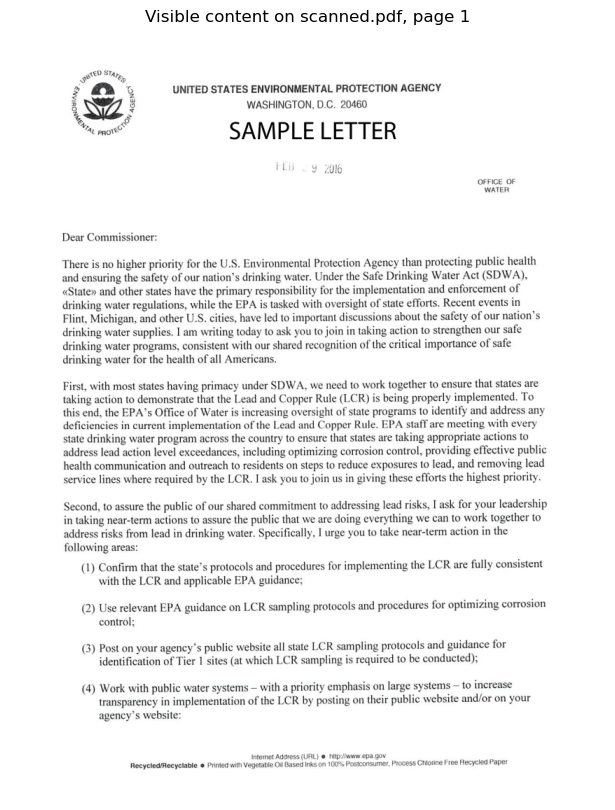

In [46]:
with pymupdf.open(SCANNED_PDF) as document:
    scanned_page = document[0]
    page_count = document.page_count
    page_rect = scanned_page.rect
    native_text = scanned_page.get_text("text")
    embedded_images = len(scanned_page.get_images(full=True))
    image_info = scanned_page.get_image_info()
    scan_pixmap = scanned_page.get_pixmap(dpi=100, alpha=False)

print("Number of pages:", page_count)
print("Native text:", repr(native_text))
print("Embedded images on page 1:", embedded_images)
for info in image_info:
    bbox = pymupdf.Rect(info["bbox"])
    effective_dpi = info["width"] / (bbox.width / 72)
    print(f"  {info['width']} x {info['height']} px displayed over",
          f"{bbox.width:.0f} x {bbox.height:.0f} pt (about {effective_dpi:.0f} dpi)")
print("Page dimensions:", page_rect)

fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(pixmap_to_array(scan_pixmap))
ax.set_title("Visible content on scanned.pdf, page 1")
ax.axis("off")
plt.show()

The rendered page shows a letterhead with the EPA logo, a faint date stamp, a heading, and a full letter, yet native extraction returns only `'SAMPLE LETTER\n'`. The page contains one embedded image of 1275 × 1650 px that covers the whole 612 × 792 pt page. This is the scan itself, at about 150 dpi, and the letter body exists only as pixels in it.

`SAMPLE LETTER` is a real text object drawn on top of the scan, and it is visibly set in a different typeface from the letterhead. To a parser, this page is one line of text plus a picture. This is also a trap for simple heuristics: a check such as "does the page contain any text?" would wrongly classify this page as born-digital. The rest of the content can only be recovered by OCR.

## 7. Partial versus full-page OCR

`get_textpage_ocr()` renders the page, runs Tesseract on it, and returns a `TextPage` that `get_text()` reads like a native one. It has two modes:

- `full=False` (partial OCR) keeps the legible native text. It removes those text objects from a temporary copy of the page, OCRs the rendered remainder, and appends the OCR result after the native text.
- `full=True` OCRs the whole rendered page, native text included, and returns only what Tesseract recognizes.

Both runs use 200 dpi. Since the scan itself is about 150 dpi, this upsamples it: Tesseract gets larger glyphs to work with, but no detail that the scan does not contain.

In [47]:
with pymupdf.open(SCANNED_PDF) as document:
    page = document[0]
    native_text = page.get_text("text")

    partial_textpage = page.get_textpage_ocr(
        language="eng",
        dpi=200,
        full=False,
        tessdata=str(TESSDATA_DIR),
    )
    full_textpage = page.get_textpage_ocr(
        language="eng",
        dpi=200,
        full=True,
        tessdata=str(TESSDATA_DIR),
    )

    partial_text = page.get_text("text", textpage=partial_textpage)
    full_text = page.get_text("text", textpage=full_textpage)

print("NATIVE EXTRACTION:\n", repr(native_text), sep="")
print("\nPARTIAL OCR (first 500 characters):\n")
print(partial_text[:500])
print("\nFULL OCR (first 500 characters):\n")
print(full_text[:500])

NATIVE EXTRACTION:
'SAMPLE LETTER\n'

PARTIAL OCR (first 500 characters):

SAMPLE LETTER
se STA.
2 re \ i}
UNITED STATES ENVIRONMENTAL PROTECTION AGENCY
3SZ &
WASHINGTON, D.C. 20460
&,
eo
AL pro
PE.
y
2016
OFFICE OF
WATER
Dear Commissioner:
There is no higher priority for the U.S. Environmental Protection Agency than protecting public health
and ensuring the safety of our nation’s drinking water. Under the Safe Drinking Water Act (SDWA),
«State» and other states have the primary responsibility for the implementation and enforcement of
drinking water regulations, while 

FULL OCR (first 500 characters):

ee ore,
2 re \ i}
UNITED STATES ENVIRONMENTAL PROTECTION AGENCY
3SZ 8
WASHINGTON, D.C. 20460
b,
=
%,
KS
“emo
SAMPLE LETTER
FEN.
9
2016
OFFICE OF
WATER
Dear Commissioner:
There is no higher priority for the U.S. Environmental Protection Agency than protecting public health
and ensuring the safety of our nation’s drinking water. Under the Safe Drinking Water Act (SDWA),
«State» and other 

The body text is recognized well in both modes. The agency name, the address, `OFFICE OF WATER`, and the opening paragraph come out correctly, including details such as `nation’s` and `«State»`.

The modes differ in how they handle `SAMPLE LETTER`. Partial OCR outputs it first, exactly as in the native text, because the OCR result is appended after the native layer. It is not repeated later because the text object was removed before the page was OCRed. Full OCR reads the heading from the pixels like everything else, so it appears in the middle of the output, at its place in Tesseract's reading order. Recognition is correct either way here, but only partial OCR guarantees the exact native string, for example if the heading were faint or damaged.

The errors are concentrated in two regions. The circular logo, with lettering around a graphic, produces fragments such as `se STA.`, `3SZ &`, and `AL pro` (partial) or `ee ore,`, `3SZ 8`, and `“emo` (full). Tesseract finds character-like shapes there but no real words, and the noise differs between the two runs. The faint date stamp is split across lines and misread as `PE.` / `y` / `2016` and `FEN.` / `9` / `2016`. Low contrast gives Tesseract weak evidence, so only the clearer year survives.

## 8. Summary and limitations

- A born-digital PDF gives exact characters, positions, and fonts, but not semantic structure. Reading order, words, equations, and tables all have to be reconstructed from geometry.
- `sort=True` fixes reading order but cannot rebuild a formula: the fraction on page 9 becomes `m(x)1` because its parts are just positioned spans. Glyphs without a Unicode mapping, such as the CMEX integral and sum signs, are extracted as the letters `R` and `P`.
- Word boxes and the block → line → span hierarchy reliably locate content and describe its typography, not its meaning.
- A figure may be vector paths (page 17) or a raster image (page 65). In the second case, even the text inside the figure is invisible to extraction.
- Table detection can report a table without recovering its structure. On page 49, a three-column table with only horizontal rules came out as one column that also absorbed the paragraphs above and below it.
- A scanned page can carry a small native text layer that hides how little text is really extractable. Partial OCR keeps that layer exactly, while full OCR re-reads everything. In both modes, the body text was recognized well, but the logo and the faint date stamp produced noise.

These results apply to the selected pages, PyMuPDF 2.1, Tesseract's English model, and a 200 dpi OCR resolution. Other documents, fonts, languages, or settings can give a different extraction order and accuracy.